# 11. Naïve Bayes Classifier (Gaussian Naïve Bayes)

## Lý thuyết & Nguyên lý

### 11.1. Định lý Bayes — nền tảng

Mô hình ước tính **xác suất hậu tri (posterior)** của lớp dựa trên dữ liệu quan sát được, theo định lý Bayes:

$$P(Y \mid X) = \frac{P(X \mid Y)\; P(Y)}{P(X)} \qquad \Leftrightarrow \qquad \underbrace{P(Y \mid X)}_{\text{hậu tri}} \propto \underbrace{P(X \mid Y)}_{\text{tương thích (likelihood)}} \times \underbrace{P(Y)}_{\text{tiên nghiệm}}$$

- **Prior $P(Y)$:** tần suất xuất hiện của từng lớp trong dữ liệu huấn luyện.
- **Likelihood $P(X \mid Y)$:** khả năng quan sát thấy bộ đặc trưng $X$ nếu biết thuộc lớp $Y$.
- **Posterior $P(Y \mid X)$:** xác suất lớp sau khi thấy dữ liệu — mô hình dự đoán lớp có posterior lớn nhất (nguyên tắc MAP).
- $P(X)$ không phụ thuộc lớp → chỉ cần so sánh **tử số**, tránh tính xác suất chung.

### 11.2. Giả định "Ngây thơ" (Naïve Assumption)

Thuật toán giả định các đặc trưng **độc lập với nhau** khi đã biết nhãn lớp — giả định rất mạnh và hầu như luôn sai trong thực tế, nhưng vẫn cho kết quả bất ngờ tốt vì mục tiêu chỉ là **so sánh thứ tự xác suất giữa các lớp** chứ không cần ước lượng xác suất tuyệt đối chính xác:

$$P(X \mid Y=c) = \prod_{j=1}^{p} P(X_j \mid Y=c)$$

### 11.3. Gaussian Naïve Bayes — với đặc trưng liên tục

Mỗi đặc trưng liên tục trong mỗi lớp được giả định theo **phân phối chuẩn (Gaussian)** với trung bình $\mu_{jc}$ và phương sai $\sigma^2_{jc}$ ước tính từ dữ liệu:

$$P(X_j = x_j \mid Y=c) = \frac{1}{\sqrt{2\pi\sigma_{jc}^2}} \exp\left(-\frac{(x_j - \mu_{jc})^2}{2\sigma_{jc}^2}\right)$$

Quyết định cuối cùng (tính trong log để tránh tràn số):

$$\hat{y} = \arg\max_c \left[\log P(Y=c) + \sum_{j=1}^{p} \log P(X_j \mid Y=c)\right]$$

**Các biến thể Naïve Bayes khác** (theo loại dữ liệu): `MultinomialNB` (tần suất từ/tài liệu), `BernoulliNB` (đặc trưng nhị phân), `ComplementNB` (chống lệch lớp, mạnh cho văn bản).


Lớp 0: mu=-1.5, sigma=1.0  |  Lớp 1: mu=1.5, sigma=1.0


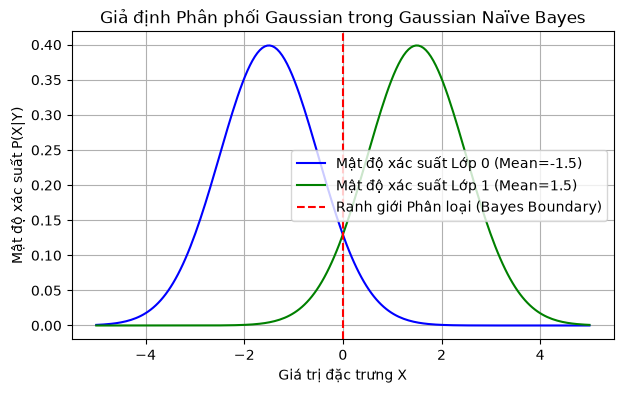

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

# 1. Sinh trục đặc trưng
x = np.linspace(-5, 5, 200)

# 2. Giả lập hàm mật độ xác suất Gaussian của 2 lớp (1 chiều)
class0 = norm.pdf(x, loc=-1.5, scale=1.0)
class1 = norm.pdf(x, loc=1.5, scale=1.0)

# 3. Vẽ hai đường cong mật độ
plt.figure(figsize=(7, 4))
plt.plot(x, class0, label='Mật độ xác suất Lớp 0 (Mean=-1.5)', color='blue')
plt.plot(x, class1, label='Mật độ xác suất Lớp 1 (Mean=1.5)', color='green')
plt.axvline(0, color='red', linestyle='--', label='Ranh giới Phân loại (Bayes Boundary)')
plt.title('Giả định Phân phối Gaussian trong Gaussian Naïve Bayes')
plt.xlabel('Giá trị đặc trưng X')
plt.ylabel('Mật độ xác suất P(X|Y)')
plt.legend()
plt.grid(True)
plt.show()

print(f"Lớp 0: mu=-1.5, sigma=1.0  |  Lớp 1: mu=1.5, sigma=1.0")


## Ý nghĩa của biểu đồ

- Hai đường cong xanh dương/xanh lá là **hàm mật độ xác suất (PDF)** của cùng một đặc trưng cho hai lớp khác nhau.
- Ranh giới phân loại lý tưởng nằm tại giao điểm hai đường cong (ở $x = 0$ trong ví dụ đối xứng này) — nơi $P(X|Y{=}0)\cdot P(Y{=}0) = P(X|Y{=}1)\cdot P(Y{=}1)$.
- Vùng overlap (hai đường chồng nhau) là nguồn **lỗi tối thiểu Bayesian** — không mô hình nào phân loại đúng 100% tại vùng này nếu chỉ dùng 1 đặc trưng.

---

## Tổng quan mô hình

### Ưu điểm

- **Rất nhanh** — huấn luyện chỉ là đếm thống kê ($O(n \cdot p)$), dự đoán $O(p)$; đặc biệt mạnh cho dữ liệu text khổ lớn.
- **Hiệu quả với dữ liệu cao chiều, thưa** (bag-of-words hàng nghìn chiều) — là baseline mặc định cho phân loại văn bản.
- **Ít dữ liệu vẫn hoạt động** — ước lượng chỉ cần trung bình/phương sai từng đặc trưng/lớp.
- **Rất ít overfitting** nhờ giả định đơn giản hóa mạnh; xác suất luôn được hiệu chỉnh tốt (calibration) với dữ liệu phù hợp giả định.
- **Dễ cập nhật** — thêm dữ liệu chỉ cần cập nhật thống kê, không huấn luyện lại từ đầu.

### Nhược điểm

- **Giả định độc lập sai trong thực tế** — khi đặc trưng tương quan mạnh (ví dụ chiều cao & cân nặng), mô hình "đếm trùng" thông tin.
- **GaussianNB không tốt với dữ liệu phi tuyến** hoặc đặc trưng phân bố lệch (cần log-transform trước).
- **Xác suất bị "cắt cụt"** — liên tục không thuộc phân phối mẫu; vùng overlap nhỏ có thể bị phân loại sai tự tin.
- Không hỗ trợ tương tác giữa các đặc trưng (như mô hình cây).

### Siêu tham số quan trọng

| Tham số | Vai trò | Gợi ý |
| :--- | :--- | :--- |
| `var_smoothing` | Phần lớn thêm vào mọi phương sai để ổn định log-determinant | Mặc định $10^{-9}$·max Var(X); tăng lên nếu dữ liệu noisy/tương quan cao |
| `priors` | Prior tường minh của các lớp | Để `None` (ước tính từ dữ liệu) hoặc khử bias thủ công |
| `fit_prior` | Có học prior hay không | `True` mặc định |

**Chọn biến thể:** `GaussianNB` (liên tục), `MultinomialNB` (tần suất/tài liệu), `BernoulliNB` (nhị phân), `ComplementNB` (văn bản lệch lớp).

### Các trường hợp sử dụng thực tế

| Lĩnh vực | Ứng dụng cụ thể | Đặc trưng đầu vào ($X$) | Lớp ($Y$) |
| :--- | :--- | :--- | :--- |
| **NLP** | Phân loại email Spam | Tần suất từ (TF/TF-IDF) | Spam / Không spam |
| **NLP** | Phát hiện cảm xúc bình luận | Bag-of-words | Tích cực / Tiêu cực |
| **Y tế** | Sàng lọc sơ bộ | Chỉ số xét nghiệm, triệu chứng | Bình thường / Bất thường |
| **Thời tiết** | Dự báo mưa trong ngày tới | Độ ẩm, áp suất, mây, gió | Có mưa / Không mưa |
| **An ninh thực phẩm** | Phân loại chất lượng mẫu | Kết quả xét nghiệm vi sinh, hóa lý | Đạt / Không đạt |

### Mẹo thực hành

- Với dữ liệu text: luôn thử `MultinomialNB` hoặc `ComplementNB` làm **baseline đầu tiên** — gần như không có mô hình nào nhanh hơn với hiệu năng tương đương ở bước đầu.
- Nếu các đặc trưng liên tục bị lệch, log-transform trước khi dùng GaussianNB.
- Kiểm tra correlation matrix — nếu nhiều cặp tương quan $> 0.9$, GaussianNB bị "phạt" vì đếm trùng thông tin; cân nhắc Linear Discriminant Analysis (LDA) thay thế.


Accuracy: 0.9111
Confusion Matrix:
[[42  5]
 [ 3 40]]
Prior các lớp      : [0.49 0.51]
Trung bình (theta_):
[[-1.009 -0.021]
 [ 0.929  0.009]]
Phương sai (var_)  :
[[0.463 1.377]
 [0.419 1.537]]


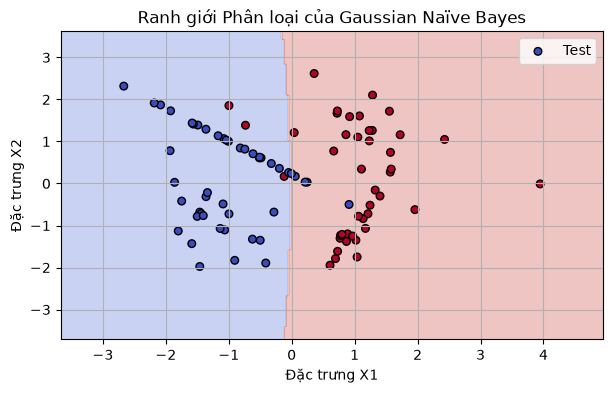

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

# 1. Dữ liệu 2 lớp, 2 đặc trưng (dễ trực quan hóa ranh giới)
X, y = make_classification(
    n_samples=300, n_features=2, n_redundant=0, n_informative=2,
    class_sep=1.0, random_state=42,
)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 2. Huấn luyện Gaussian Naïve Bayes
gnb = GaussianNB().fit(X_train, y_train)
y_pred = gnb.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")
print(f"Prior các lớp      : {np.round(gnb.class_prior_, 3)}")
print(f"Trung bình (theta_):\n{gnb.theta_.round(3)}")
print(f"Phương sai (var_)  :\n{gnb.var_.round(3)}")

# 3. Vẽ ranh giới quyết định
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 250),
    np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 250),
)
Z = gnb.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(7, 4))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='coolwarm',
            edgecolor='k', s=30, label='Test')
plt.title('Ranh giới Phân loại của Gaussian Naïve Bayes')
plt.xlabel('Đặc trưng X1')
plt.ylabel('Đặc trưng X2')
plt.legend()
plt.grid(True)
plt.show()


## Giải thích kết quả

- **`class_prior_`**: xác suất tiên nghiệm từng lớp — tỷ lệ xuất hiện của lớp trong dữ liệu huấn luyện.
- **`theta_`** và **`var_`**: trung bình và phương sai ước tính cho **từng đặc trưng × từng lớp** — chính là các tham số $\mu_{jc}, \sigma^2_{jc}$ trong công thức Gaussian ở phần lý thuyết. Hai dòng khác nhau của `theta_` cho thấy hai lớp phân bố lệch nhau — đó là "thông tin" mô hình dùng để phân loại.
- **Ranh giới** (trong trường hợp đặc trưng độc lập và cùng phương sai) gần như là **một đường thẳng** — nếu hai lớp có phương sai khác nhau đáng kể, ranh giới có thể cong (mô hình GaussianNB không giả định phương sai chung như LDA).
